# Projeto Final — Robô Autônomo V.I.N.I. (Navegação Urbana no CoppeliaSim)

Este notebook concentra o pipeline completo de navegação autônoma do triciclo **V.I.N.I.**, dividido em 4 módulos integrados:

1. **Módulo 1 — Mapeamento (Occupancy Grid 2D em Dupla Camada)**:
   - **Camada de Navegação (`grid_rrt.npy`)**: Livre (`0`) apenas no asfalto das vias e rotatórias (com inflação C-Space para segurança contra o meio-fio); Ocupado (`1`) em calçadas, canteiros, grama e prédios.
   - **Camada de Obstáculos Físicos (`grid_mcl.npy`)**: Ocupado (`1`) apenas nos **20 prédios físicos 3D** que possuem altura e refletem o feixe do LiDAR 2D (`fastHokuyo`); Livre (`0`) no asfalto, calçadas e grama.
2. **Módulo 2 — Localização Probabilística (MCL / Filtro de Partículas)** *(próxima etapa)*
3. **Módulo 3 — Planejamento de Caminhos (RRT com restrição cinemática de curvatura)** *(próxima etapa)*
4. **Módulo 4 — Controle Cinemático (Modelo Bicicleta / Ackermann — Path Follower)** *(próxima etapa)*

![Pipeline da Arquitetura](mapeamento/pipeline_arquitetura.png)

---
## Módulo 1: Mapeamento e Geração das Grades de Ocupação (`grid_rrt` e `grid_mcl`)

### Célula 1: Importar bibliotecas e carregar a imagem do cenário urbano

Mapa carregado com sucesso! Dimensões da matriz: W=976 cols x H=1024 rows


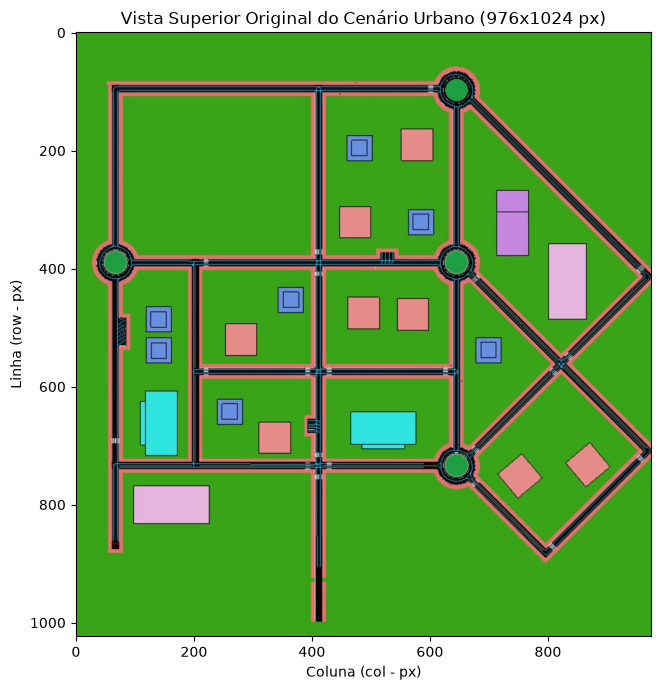

In [1]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Garante que a pasta mapeamento/ seja encontrada tanto rodando da raiz quanto de subpastas
BASE_DIR = os.path.abspath(".")
if os.path.basename(BASE_DIR) == "mapeamento":
    MAP_DIR = BASE_DIR
else:
    MAP_DIR = os.path.join(BASE_DIR, "mapeamento")

os.makedirs(MAP_DIR, exist_ok=True)
IMG_PATH = os.path.join(MAP_DIR, "mapa_cidade.jpg")

img_bgr = cv2.imread(IMG_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"Imagem não encontrada em: {IMG_PATH}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
H, W, _ = img_rgb.shape
print(f"Mapa carregado com sucesso! Dimensões da matriz: W={W} cols x H={H} rows")

plt.figure(figsize=(7, 7))
plt.imshow(img_rgb)
plt.title(f"Vista Superior Original do Cenário Urbano ({W}x{H} px)")
plt.xlabel("Coluna (col - px)")
plt.ylabel("Linha (row - px)")
plt.tight_layout()
plt.show()

### Célula 2: Segmentação por Cor e Topologia (Asfalto Contínuo vs. Prédios 3D)

- **Separação dos Prédios (`grid_mcl.npy`)**: Na imagem do cenário, alguns prédios têm a mesma cor salmão das calçadas. Porém, **todos os 20 prédios** estão fisicamente isolados dentro dos quarteirões de grama, enquanto as calçadas formam um único componente conexo colado à malha viária. Combinando limiarização da grama com análise de componentes conexas (`cv2.connectedComponentsWithStats`), separamos com 100% de precisão os **20 prédios 3D** (azuis, salmão, ciano, roxo e rosa) sem confundir nenhum pixel de calçada.
- **Separação do Asfalto**: Dentro da malha viária, removemos as calçadas salmão e aplicamos fechamento morfológico (`cv2.MORPH_CLOSE`) para absorver as faixas de pedestres brancas e linhas-guia azuis, tornando o asfalto **100% contínuo**.

In [2]:
# Conversão para int16 evita overflow de uint8 em comparações de canais RGB
rgb_i16 = img_rgb.astype(np.int16)

# 1. Máscara da grama (fundo verde e ilhas centrais das rotatórias)
grass_mask = (
    (rgb_i16[:, :, 1] > 110)
    & (rgb_i16[:, :, 1] > rgb_i16[:, :, 0] + 40)
    & (rgb_i16[:, :, 1] > rgb_i16[:, :, 2] + 50)
)
non_grass = (~grass_mask).astype(np.uint8)

# 2. Análise topológica de componentes conexas do que não é grama:
#    - O maior componente (~172 mil px) é a malha viária + calçadas.
#    - Os outros 20 componentes (área > 500 px) são exatamente os 20 prédios físicos 3D!
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(non_grass, connectivity=8)
comp_areas = [
    (i, stats[i, cv2.CC_STAT_AREA])
    for i in range(1, num_labels)
    if stats[i, cv2.CC_STAT_AREA] > 500
]
comp_areas.sort(key=lambda x: -x[1])

road_comp_id = comp_areas[0][0]
building_ids = [idx for idx, _ in comp_areas[1:]]

# Camada de Obstáculos Físicos para o LiDAR / MCL (1 = Prédio 3D, 0 = Livre para o laser)
grid_mcl = np.isin(labels, building_ids).astype(np.uint8)
kernel_predios = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
grid_mcl = cv2.morphologyEx(grid_mcl, cv2.MORPH_CLOSE, kernel_predios)

# 3. Isolar o Asfalto dentro da malha viária (removendo as calçadas salmão)
road_network_mask = (labels == road_comp_id)
sidewalk_color = (
    (rgb_i16[:, :, 0] > 115)
    & (rgb_i16[:, :, 0] > rgb_i16[:, :, 1] + 25)
    & (rgb_i16[:, :, 0] > rgb_i16[:, :, 2] + 15)
)
raw_asphalt = (road_network_mask & (~sidewalk_color)).astype(np.uint8)

# Abertura 3x3 (remove borda de 1px de compressão JPEG) + Fechamento 7x7 (une faixas de pedestres e marcações)
k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
asphalt_clean = cv2.morphologyEx(raw_asphalt, cv2.MORPH_OPEN, k_open)
asphalt_clean = cv2.morphologyEx(asphalt_clean, cv2.MORPH_CLOSE, k_close)

# Seleciona o componente conexo único da pista de asfalto
n_a, lbl_a, st_a, _ = cv2.connectedComponentsWithStats(asphalt_clean, connectivity=8)
main_asphalt_id = 1 + int(np.argmax(st_a[1:, cv2.CC_STAT_AREA]))
asphalt_mask = (lbl_a == main_asphalt_id).astype(np.uint8)
asphalt_mask = cv2.morphologyEx(asphalt_mask, cv2.MORPH_CLOSE, k_close)

print(f"Prédios 3D detectados para o MCL: {len(building_ids)} prédios ({grid_mcl.sum()} pixels ocupados)")
print(f"Asfalto contínuo extraído: {asphalt_mask.sum()} pixels livres antes da inflação C-Space")

Prédios 3D detectados para o MCL: 20 prédios (75507 pixels ocupados)
Asfalto contínuo extraído: 82732 pixels livres antes da inflação C-Space


### Célula 3: Inflação de Obstáculos (C-Space) para a Camada de Navegação (`grid_rrt.npy`)

Dilatamos os obstáculos (ou equivalentemente erodimos a máscara livre de asfalto) por um raio `INFLATION_RADIUS_PX` equivalente à metade da largura do VINI + margem de segurança, garantindo que o planejador **RRT** nunca gere rotas raspando no meio-fio das calçadas ou das rotatórias.

In [3]:
# Raio de inflação em pixels (ajustável: 2 px mantém ~6-8 px de corredor central livre e 100% conectado)
INFLATION_RADIUS_PX = 2

# Mapa binário bruto de navegação (0 = Asfalto Livre, 1 = Calçada/Grama/Prédios)
grid_rrt_raw = (1 - asphalt_mask).astype(np.uint8)

if INFLATION_RADIUS_PX > 0:
    k_size = 2 * INFLATION_RADIUS_PX + 1
    k_inflate = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))
    # Dilatar os obstáculos (1) equivale a inflar o C-Space para longe do meio-fio
    grid_rrt = cv2.dilate(grid_rrt_raw, k_inflate)
else:
    grid_rrt = grid_rrt_raw.copy()

# Verificação topológica: garante que a pista livre (grid_rrt == 0) continua 100% conectada
free_rrt = (grid_rrt == 0).astype(np.uint8)
n_conn, _, st_conn, _ = cv2.connectedComponentsWithStats(free_rrt, connectivity=8)
largest_free = st_conn[1:, cv2.CC_STAT_AREA].max() if n_conn > 1 else 0
pct_conn = 100.0 * largest_free / max(1, free_rrt.sum())

print(f"Raio de inflação C-Space aplicado: {INFLATION_RADIUS_PX} px (kernel {2*INFLATION_RADIUS_PX+1}x{2*INFLATION_RADIUS_PX+1})")
print(f"Pixels navegáveis após inflação (grid_rrt == 0): {free_rrt.sum()} px ({pct_conn:.1f}% em malha única conectada)")

Raio de inflação C-Space aplicado: 2 px (kernel 5x5)
Pixels navegáveis após inflação (grid_rrt == 0): 55666 px (100.0% em malha única conectada)


### Célula 4: Calibração Mundo Real (CoppeliaSim) $\leftrightarrow$ Pixels da Grade

Para converter qualquer coordenada $(x, y)$ do CoppeliaSim em índices $(col, row)$ da matriz $(H \times W)$:

$$col = \left\lfloor \frac{x - x_{\min}}{\text{res}} \right\rfloor, \qquad row = (H - 1) - \left\lfloor \frac{y - y_{\min}}{\text{res}} \right\rfloor$$

Abaixo detectamos automaticamente os centros em pixels das **4 rotatórias** da imagem para servir como marcos visuais de calibração rápida com o CoppeliaSim.

In [4]:
# Detecta automaticamente os centros em pixels (col, row) das 4 ilhas verdes das rotatórias
g_num, g_labels, g_stats, g_centroids = cv2.connectedComponentsWithStats(grass_mask.astype(np.uint8), connectivity=8)
rotatorias_px = []
for i in range(1, g_num):
    area = g_stats[i, cv2.CC_STAT_AREA]
    if 800 <= area <= 3500:
        col_c, row_c = g_centroids[i]
        rotatorias_px.append((float(col_c), float(row_c)))

# Ordena por linha (row) e coluna (col)
rotatorias_px.sort(key=lambda p: (round(p[1] / 100), p[0]))
nomes_rotatorias = [
    "Rotatória Superior Direita",
    "Rotatória Central Esquerda",
    "Rotatória Central Direita",
    "Rotatória Inferior Direita",
]
marcos_px = dict(zip(nomes_rotatorias, rotatorias_px))
print("Marcos visuais detectados na imagem (col, row):")
for nome, (c, r) in marcos_px.items():
    print(f"  - {nome}: col = {c:.1f} px, row = {r:.1f} px")


def calibrar_por_dois_pontos(p1_world, p1_px, p2_world, p2_px, height=H, width=W):
    """
    Calcula resolution (m/pixel), origin_x (x_min) e origin_y (y_min)
    a partir de dois marcos conhecidos: (x, y) no CoppeliaSim e (col, row) na imagem.
    """
    x1, y1 = p1_world
    c1, r1 = p1_px
    x2, y2 = p2_world
    c2, r2 = p2_px

    res_x = abs(x2 - x1) / max(1e-6, abs(c2 - c1))
    res_y = abs(y2 - y1) / max(1e-6, abs(r2 - r1))
    res = 0.5 * (res_x + res_y)

    origin_x = x1 - c1 * res
    origin_y = y1 - ((height - 1) - r1) * res
    return {
        "resolution": float(res),
        "resolution_x": float(res_x),
        "resolution_y": float(res_y),
        "origin_x": float(origin_x),
        "origin_y": float(origin_y),
        "width": int(width),
        "height": int(height),
    }


# -------------------------------------------------------------------------
# CONFIGURAÇÃO DE CALIBRAÇÃO (Ajuste p1_world e p2_world com os valores lidos no CoppeliaSim)
# Por padrão, assumimos um terreno urbano de 50m de largura centrado em (0, 0),
# ou você pode descomentar calibrar_por_dois_pontos() com as posições reais de 2 rotatórias!
# -------------------------------------------------------------------------
USAR_CALIBRACAO_DOIS_PONTOS = False

if USAR_CALIBRACAO_DOIS_PONTOS:
    # Exemplo: substitua pelas coordenadas (x, y) lidas no CoppeliaSim para as duas rotatórias
    p1_world = (7.20, 20.10)   # (x, y) da Rotatória Superior Direita no CoppeliaSim
    p2_world = (-21.60, 5.60)  # (x, y) da Rotatória Central Esquerda no CoppeliaSim
    map_config = calibrar_por_dois_pontos(
        p1_world, marcos_px["Rotatória Superior Direita"],
        p2_world, marcos_px["Rotatória Central Esquerda"],
    )
else:
    # Escala padrão: ~0.05 m/pixel (5 cm por pixel) centrada na origem do CoppeliaSim
    DEFAULT_RES = 0.05
    map_config = {
        "resolution": DEFAULT_RES,
        "origin_x": -(W * DEFAULT_RES) / 2.0,
        "origin_y": -(H * DEFAULT_RES) / 2.0,
        "width": int(W),
        "height": int(H),
    }

map_config["inflation_radius_px"] = int(INFLATION_RADIUS_PX)
map_config["inflation_radius_m"] = float(INFLATION_RADIUS_PX * map_config["resolution"])
map_config["landmarks_px"] = {k: {"col": round(v[0], 2), "row": round(v[1], 2)} for k, v in marcos_px.items()}


def world_to_grid(x, y, cfg=map_config):
    """Converte coordenada (x, y) [metros] do CoppeliaSim para (col, row) [pixels] da matriz."""
    res = cfg["resolution"]
    col = int(np.floor((x - cfg["origin_x"]) / res))
    row = (cfg["height"] - 1) - int(np.floor((y - cfg["origin_y"]) / res))
    return col, row


def grid_to_world(col, row, cfg=map_config):
    """Converte pixel (col, row) da matriz para coordenada (x, y) [metros] no CoppeliaSim."""
    res = cfg["resolution"]
    x = cfg["origin_x"] + (col + 0.5) * res
    y = cfg["origin_y"] + ((cfg["height"] - 1 - row) + 0.5) * res
    return float(x), float(y)


print("\nConfiguração de Calibração (map_config):")
print(json.dumps(map_config, indent=2, ensure_ascii=False))

Marcos visuais detectados na imagem (col, row):
  - Rotatória Superior Direita: col = 645.3 px, row = 97.5 px
  - Rotatória Central Esquerda: col = 67.3 px, row = 389.5 px
  - Rotatória Central Direita: col = 645.2 px, row = 389.3 px
  - Rotatória Inferior Direita: col = 645.0 px, row = 733.3 px

Configuração de Calibração (map_config):
{
  "resolution": 0.05,
  "origin_x": -24.400000000000002,
  "origin_y": -25.6,
  "width": 976,
  "height": 1024,
  "inflation_radius_px": 2,
  "inflation_radius_m": 0.1,
  "landmarks_px": {
    "Rotatória Superior Direita": {
      "col": 645.33,
      "row": 97.49
    },
    "Rotatória Central Esquerda": {
      "col": 67.28,
      "row": 389.51
    },
    "Rotatória Central Direita": {
      "col": 645.17,
      "row": 389.33
    },
    "Rotatória Inferior Direita": {
      "col": 644.99,
      "row": 733.3
    }
  }
}


### Célula 5: Exportação Padronizada (`grid_rrt.npy`, `grid_mcl.npy`, `map_config.json`) e Visualização

Salva os arquivos padronizados na pasta `mapeamento/` para consumo direto pelos módulos de **MCL**, **RRT** e **Controle Cinemático**, e plota as camadas lado a lado.

Arquivos exportados com sucesso em 'c:\Users\Gabriel\Desktop\Projeto_VINI\mapeamento':
  - grid_rrt.npy   shape=(1024, 976), dtype=uint8 (0=Livre, 1=Ocupado)
  - grid_mcl.npy   shape=(1024, 976), dtype=uint8 (0=Livre, 1=Prédio 3D)
  - map_config.json


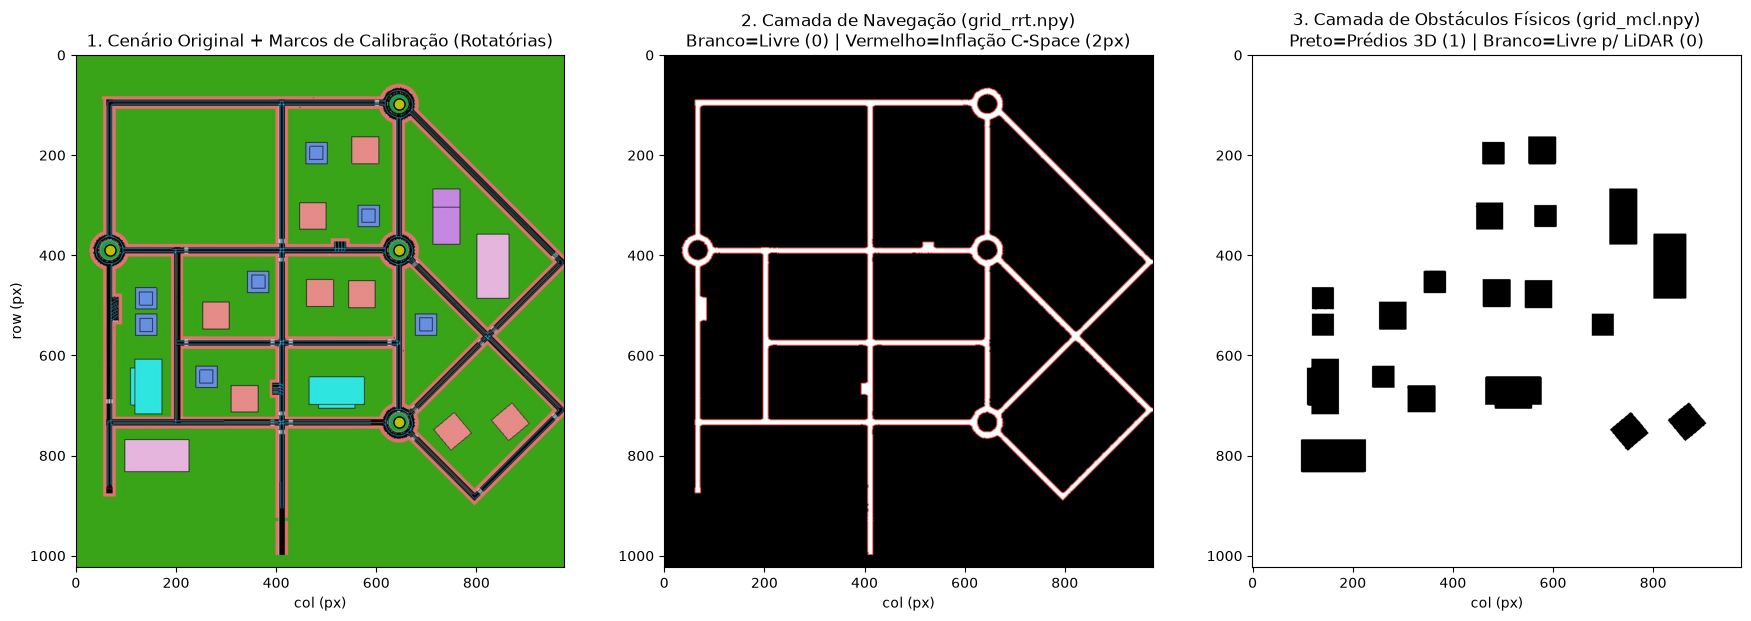

In [5]:
rrt_path = os.path.join(MAP_DIR, "grid_rrt.npy")
mcl_path = os.path.join(MAP_DIR, "grid_mcl.npy")
cfg_path = os.path.join(MAP_DIR, "map_config.json")
fig_path = os.path.join(MAP_DIR, "visualizacao_mapas.png")

np.save(rrt_path, grid_rrt)
np.save(mcl_path, grid_mcl)
with open(cfg_path, "w", encoding="utf-8") as f:
    json.dump(map_config, f, indent=2, ensure_ascii=False)

print(f"Arquivos exportados com sucesso em '{MAP_DIR}':")
print(f"  - grid_rrt.npy   shape={grid_rrt.shape}, dtype={grid_rrt.dtype} (0=Livre, 1=Ocupado)")
print(f"  - grid_mcl.npy   shape={grid_mcl.shape}, dtype={grid_mcl.dtype} (0=Livre, 1=Prédio 3D)")
print(f"  - map_config.json")

# Visualização comparativa das 3 representações
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Painel 1: Imagem original + Marcos das 4 rotatórias
axes[0].imshow(img_rgb)
for nome, (c, r) in marcos_px.items():
    axes[0].plot(c, r, "yo", markersize=8, markeredgecolor="black")
axes[0].set_title("1. Cenário Original + Marcos de Calibração (Rotatórias)")
axes[0].set_xlabel("col (px)")
axes[0].set_ylabel("row (px)")

# Painel 2: Camada de Navegação RRT (mostrando C-Space inflado vs pista livre)
# Visualização colorida: Branco = Pista Livre (0), Vermelho = Margem C-Space inflada, Preto = Obstáculo (1)
vis_rrt = np.zeros((H, W, 3), dtype=np.uint8)
vis_rrt[grid_rrt == 0] = [255, 255, 255]                    # Livre após inflação (Branco)
cspace_band = (grid_rrt_raw == 0) & (grid_rrt == 1)
vis_rrt[cspace_band] = [255, 90, 90]                        # Margem C-Space junto ao meio-fio (Vermelho)
axes[1].imshow(vis_rrt)
axes[1].set_title(f"2. Camada de Navegação (grid_rrt.npy)\nBranco=Livre (0) | Vermelho=Inflação C-Space ({INFLATION_RADIUS_PX}px)")
axes[1].set_xlabel("col (px)")

# Painel 3: Camada de Obstáculos Físicos MCL (1 = Prédios 3D que refletem o LiDAR)
axes[2].imshow(1 - grid_mcl, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("3. Camada de Obstáculos Físicos (grid_mcl.npy)\nPreto=Prédios 3D (1) | Branco=Livre p/ LiDAR (0)")
axes[2].set_xlabel("col (px)")

plt.tight_layout()
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()